# 3.4.1 Boundary conditions: strong and dilute uptake

Reads two run sets, each with the five gas-phase pressure-velocity settings:

- strong uptake, `simulations/`: Marx et al. (2014) T3, T9, T15, T21 at $10^6$ Pa (this directory);
- dilute uptake, `../3.4.1_boundary_conditions_bea_dilute/simulations/`: BEA with seven C$_7$ isomers in helium.

Both are parameterized so that all settings coincide once the column is filled with the feed (`conversions.md`).
The runs use ROS34PW2, with which every setting completes (with CVODE, the fixed-velocity and imposed-pressure
settings stalled on some Marx runs); `run_status` reports how far each run got.

The paper panels are written to `ruptura-2.0-paper/figures/boundary_conditions/`.

In [1]:
import json
import re
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "simulations" / "index.json").is_file():
    raise FileNotFoundError("Run this notebook from validation/3.4.1_boundary_conditions_marx_10bar after run.py.")
REPOSITORY = ROOT.parent.parent
BEA_ROOT = ROOT.parent / "3.4.1_boundary_conditions_bea_dilute"
REFERENCE_ROOT = REPOSITORY / "validation" / "3.3.1_energy_balance_marx_ternary" / "marx2" / "reference_digitized"
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "boundary_conditions"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MODES = [
    "InletVelocityOutletPressure",
    "InletPressureOutletPressure",
    "InletPressureInletVelocity",
    "FixedPressureInletVelocity",
    "FixedVelocity",
]
# Legend label: the quantities each setting prescribes (Table S7 of the paper).
MODE_LABELS = {
    "InletVelocityOutletPressure": r"$v_{\mathrm{in}}$, $P_{\mathrm{out}}$",
    "InletPressureOutletPressure": r"$P_{\mathrm{in}}$, $P_{\mathrm{out}}$",
    "InletPressureInletVelocity": r"$P_{\mathrm{in}}$, $v_{\mathrm{in}}$",
    "FixedPressureInletVelocity": r"$P(z)$",
    "FixedVelocity": r"$v(z)$",
}
MODE_COLORS = dict(zip(MODES, ("C0", "C1", "C2", "C3", "C4")))
MARX_RUNS = ["T3", "T9", "T15", "T21"]
PROFILE_TIME = 20.0  # s, early in the breakthrough, while the settings differ most

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 10,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
@lru_cache(maxsize=None)
def data_column_index(path_string, heading):
    """Resolve a one-based Ruptura '# column N:' header to a NumPy index (as in marx2/create.ipynb)."""
    prefix = heading.casefold()
    with Path(path_string).open("rt", encoding="utf-8") as handle:
        for line in handle:
            if not line.startswith("#"):
                break
            if line.startswith("# column "):
                number_text, description = line[9:].split(":", 1)
                if description.strip().casefold().startswith(prefix):
                    return int(number_text) - 1
    raise ValueError(f"Column heading {heading!r} not found in {path_string}")


@lru_cache(maxsize=None)
def read_output(path_string, headings):
    """Columns of a Ruptura output file as arrays of shape (complete output blocks, grid nodes)."""
    columns = [data_column_index(path_string, "Time, t"), data_column_index(path_string, "Column position")]
    columns += [data_column_index(path_string, heading) for heading in headings]
    data = pd.read_csv(path_string, sep=r"\s+", comment="#", header=None, usecols=columns)[[*columns]].to_numpy()
    nodes = int(np.argmax(data[1:, 1] < data[:-1, 1])) + 1
    blocks = len(data) // nodes
    data = data[: blocks * nodes].reshape(blocks, nodes, len(columns))
    return 60.0 * data[:, 0, 0], data[0, :, 1], data[:, :, 2:]


def component_files(directory):
    """Component output files of a run, in component order, with their names."""
    files = sorted(directory.glob("component_*.data"), key=lambda path: int(path.name.split("_")[1]))
    return [(path.name.split("_", 2)[2].removesuffix(".data"), path) for path in files]


def run_status(directory):
    """'completed', 'failed' (Ruptura error), or 'stopped', and the last simulated time [s]."""
    log = (directory / "run.log").read_text()
    times = re.findall(r"time:\s*([0-9.eE+-]+) \[s\]", log)
    last = float(times[-1]) if times else 0.0
    if "Final time:" in log:
        return "completed", last
    return ("failed" if "Error" in log else "stopped"), last


def feed_mole_fraction(directory, name):
    simulation = json.loads((directory / "simulation.json").read_text())
    total = sum(component["GasPhaseMolFraction"] for component in simulation["Components"])
    return next(c["GasPhaseMolFraction"] for c in simulation["Components"] if c["Name"] == name) / total


def outlet_mole_fraction(directory, name):
    path = next(path for component, path in component_files(directory) if component == name)
    time, _, values = read_output(str(path), ("Mole fraction",))
    return time, values[:, -1, 0]


def breakthrough_time(directory, name):
    """t50 of one component from the outlet mole fraction, or NaN if the run did not get there."""
    time, fraction = outlet_mole_fraction(directory, name)
    normalized = fraction / feed_mole_fraction(directory, name)
    if not (normalized >= 0.5).any():
        return float("nan")
    i = int(np.argmax(normalized >= 0.5))
    return float(np.interp(0.5, normalized[i - 1:i + 1], time[i - 1:i + 1]))


def profiles_at(directory, time):
    """Position [m], interstitial velocity [m/s], and total gas concentration [mol/m3] at the block nearest time."""
    times, position, values = read_output(str(directory / "column.data"), ("Interstitial gas velocity",))
    block = int(np.argmin(np.abs(times - time)))
    total = np.zeros_like(position)
    for _, path in component_files(directory):
        _, _, concentration = read_output(str(path), ("Concentration, c_i",))
        total += concentration[block, :, 0]
    return times[block], position, values[block, :, 0], total


def load_reference(run):
    data = np.loadtxt(REFERENCE_ROOT / run / "exp-CO2.csv", delimiter=",")
    return data[:, 0], data[:, 1]


def marx_directory(run, mode):
    entry = next(e for e in MARX_INDEX if e["run"] == run and e["boundary_condition"] == mode)
    return ROOT / entry["directory"]


def bea_directory(mode):
    entry = next(e for e in BEA_INDEX if e["boundary_condition"] == mode)
    return BEA_ROOT / entry["directory"]

In [3]:
MARX_INDEX = json.loads((ROOT / "simulations" / "index.json").read_text())
BEA_INDEX = json.loads((BEA_ROOT / "simulations" / "index.json").read_text())

rows = []
for run in MARX_RUNS:
    for mode in MODES:
        directory = marx_directory(run, mode)
        status, last = run_status(directory)
        rows.append({"case": run, "mode": mode, "status": status, "last_time_s": last,
                     "key_component": "CO2", "t50_s": breakthrough_time(directory, "CO2")})
for mode in MODES:
    directory = bea_directory(mode)
    status, last = run_status(directory)
    rows.append({"case": "BEA", "mode": mode, "status": status, "last_time_s": last,
                 "key_component": "nC7", "t50_s": breakthrough_time(directory, "nC7")})
STATUS = pd.DataFrame(rows)
reference_t50 = STATUS[STATUS["mode"] == "InletVelocityOutletPressure"].set_index("case")["t50_s"]
STATUS["relative_t50_shift"] = STATUS["t50_s"] / STATUS["case"].map(reference_t50) - 1.0
STATUS.loc[STATUS["status"] != "completed", "relative_t50_shift"] = np.nan
STATUS

,case,mode,status,last_time_s,key_component,t50_s,relative_t50_shift
0,T3,InletVelocityOutletPressure,completed,4000.0,CO2,768.523035,0.000000
1,T3,InletPressureOutletPressure,completed,4000.0,CO2,671.937316,-0.125677
2,T3,InletPressureInletVelocity,completed,4000.0,CO2,768.520411,-0.000003
3,T3,FixedPressureInletVelocity,completed,4000.0,CO2,767.621190,-0.001173
4,T3,FixedVelocity,completed,4000.0,CO2,768.625459,0.000133
5,T9,InletVelocityOutletPressure,completed,4000.0,CO2,589.107232,0.000000
6,T9,InletPressureOutletPressure,completed,4000.0,CO2,509.331658,-0.135418
7,T9,InletPressureInletVelocity,completed,4000.0,CO2,589.105293,-0.000003
8,T9,FixedPressureInletVelocity,completed,4000.0,CO2,588.169556,-0.001592
9,T9,FixedVelocity,completed,4000.0,CO2,588.948739,-0.000269


## (a) T15 outlet CO$_2$ mole fraction

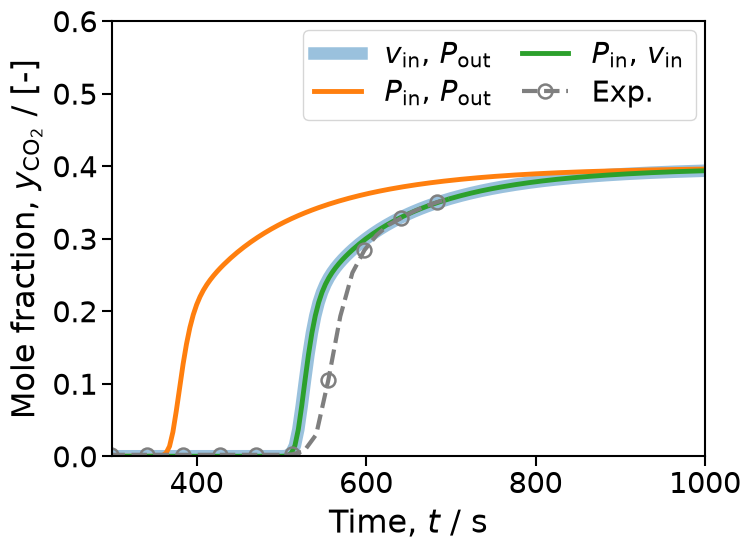

In [4]:
run = "T15"
fig, ax = plt.subplots()
for mode, width in (("InletVelocityOutletPressure", 9.0), ("InletPressureOutletPressure", 3.5),
                    ("InletPressureInletVelocity", 3.5)):
    time, fraction = outlet_mole_fraction(marx_directory(run, mode), "CO2")
    ax.plot(time, fraction, color=MODE_COLORS[mode], linestyle="-", linewidth=width,
            alpha=0.45 if width > 4.0 else 1.0, label=MODE_LABELS[mode])
time, fraction = load_reference(run)
ax.plot(time, fraction, color="C7", linestyle="--", marker="o", markerfacecolor="none", markevery=3,
        label="Exp.")
ax.set_xlim(300.0, 1000.0)
ax.set_ylim(0.0, 0.6)
ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Mole fraction, $y_{\mathrm{CO_2}}$ / [-]")
ax.legend(loc="upper right", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "boundary_conditions_T15_CO2.pdf", dpi=300)
plt.show()

## (b) T15 interstitial velocity along the column

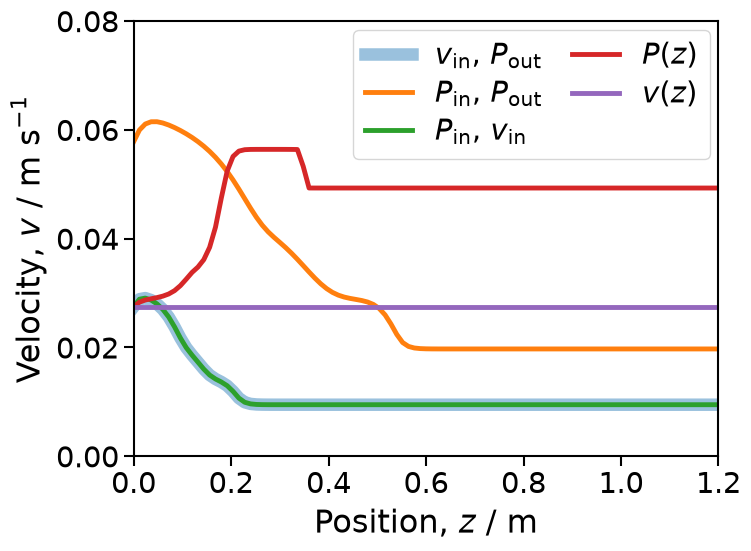

In [5]:
run = "T15"
fig, ax = plt.subplots()
for mode in MODES:
    time, position, velocity, _ = profiles_at(marx_directory(run, mode), PROFILE_TIME)
    width = 9.0 if mode == "InletVelocityOutletPressure" else 3.5
    ax.plot(position, velocity, color=MODE_COLORS[mode], linestyle="-", linewidth=width,
            alpha=0.45 if width > 4.0 else 1.0, label=MODE_LABELS[mode])
ax.set_xlim(0.0, 1.2)
ax.set_ylim(0.0, 0.08)
ax.set_xlabel(r"Position, $z$ / m")
ax.set_ylabel(r"Velocity, $v$ / m s$^{-1}$")
ax.legend(loc="upper right", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "boundary_conditions_T15_velocity.pdf", dpi=300)
plt.show()

## (c) T15 total gas concentration along the column

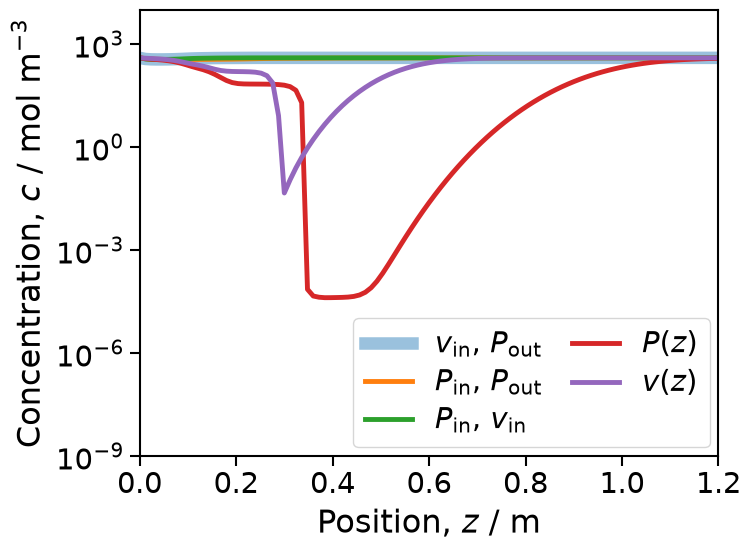

In [6]:
run = "T15"
fig, ax = plt.subplots()
for mode in MODES:
    time, position, _, total = profiles_at(marx_directory(run, mode), PROFILE_TIME)
    width = 9.0 if mode == "InletVelocityOutletPressure" else 3.5
    ax.plot(position, total, color=MODE_COLORS[mode], linestyle="-", linewidth=width,
            alpha=0.45 if width > 4.0 else 1.0, label=MODE_LABELS[mode])
ax.set_yscale("log")
ax.set_xlim(0.0, 1.2)
ax.set_ylim(1.0e-9, 1.0e4)
ax.set_yticks([1.0e-9, 1.0e-6, 1.0e-3, 1.0e0, 1.0e3])
ax.set_xlabel(r"Position, $z$ / m")
ax.set_ylabel(r"Concentration, $c$ / mol m$^{-3}$")
ax.legend(loc="lower right", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "boundary_conditions_T15_concentration.pdf", dpi=300)
plt.show()

## (d) Breakthrough-time shift relative to the inlet-velocity/outlet-pressure setting

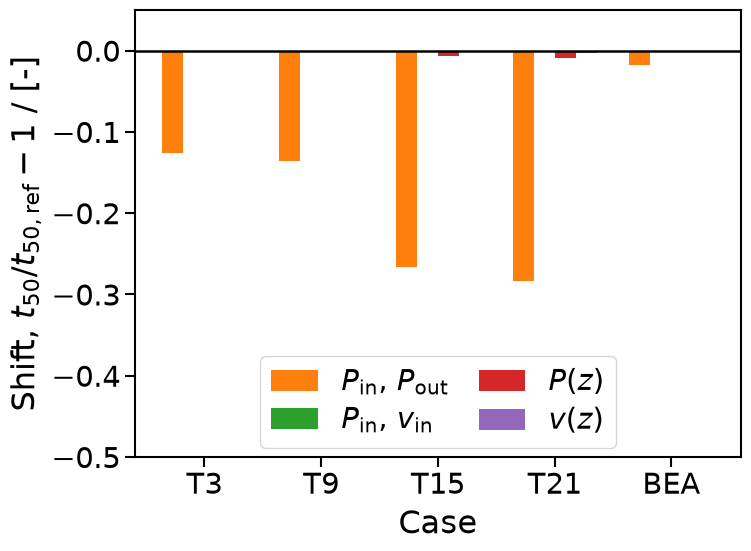

In [7]:
cases = [*MARX_RUNS, "BEA"]
positions = np.arange(len(cases))
compared = MODES[1:]  # the shift of the reference setting is zero by definition
width = 0.18

fig, ax = plt.subplots()
for offset, mode in zip(np.linspace(-1.5, 1.5, len(compared)) * width, compared):
    subset = STATUS[STATUS["mode"] == mode].set_index("case").loc[cases]
    shift = subset["relative_t50_shift"].to_numpy(dtype=float)
    ax.bar(positions + offset, np.nan_to_num(shift), width=width, color=MODE_COLORS[mode], label=MODE_LABELS[mode])
    missing = ~np.isfinite(shift)
    ax.plot(positions[missing] + offset, np.zeros(missing.sum()), linestyle="None", marker="x", markersize=14,
            markeredgewidth=3.0, color=MODE_COLORS[mode])
if STATUS.loc[STATUS["mode"].isin(compared), "relative_t50_shift"].isna().any():
    ax.plot([], [], linestyle="None", marker="x", markersize=14, markeredgewidth=3.0, color="C7", label="Not completed")
ax.axhline(0.0, color="black", linewidth=1.8)
ax.set_xticks(positions, cases)
ax.set_ylim(-0.5, 0.05)
ax.set_xlabel("Case")
ax.set_ylabel(r"Shift, $t_{50}/t_{50,\mathrm{ref}} - 1$ / [-]")
ax.legend(loc="lower center", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "boundary_conditions_t50_shift.pdf", dpi=300)
plt.show()

## Numbers quoted in the paper

In [8]:
print(STATUS.to_string(index=False, float_format=lambda value: f"{value:.4g}"))
for run in ["T15"]:
    for mode in MODES:
        time, position, velocity, total = profiles_at(marx_directory(run, mode), PROFILE_TIME)
        print(f"{run} {mode:28s} t={time:5.1f} s  v(0)={velocity[0]:.4f}  v(L)={velocity[-1]:.4f}  "
              f"min v={velocity.min():.4f}  max v={velocity.max():.4f}  min c_tot={total.min():.3g}")
for mode in MODES:
    directory = bea_directory(mode)
    names = [name for name, _ in component_files(directory) if name != "Helium"]
    shifts = [breakthrough_time(directory, name) / breakthrough_time(bea_directory(MODES[0]), name) - 1.0 for name in names]
    print(f"BEA {mode:28s} max |t50 shift| over the isomers: {np.nanmax(np.abs(shifts)):.2e}")

case                        mode    status  last_time_s key_component  t50_s  relative_t50_shift
  T3 InletVelocityOutletPressure completed         4000           CO2  768.5                   0
  T3 InletPressureOutletPressure completed         4000           CO2  671.9             -0.1257
  T3  InletPressureInletVelocity completed         4000           CO2  768.5          -3.415e-06
  T3  FixedPressureInletVelocity completed         4000           CO2  767.6           -0.001173
  T3               FixedVelocity completed         4000           CO2  768.6           0.0001333
  T9 InletVelocityOutletPressure completed         4000           CO2  589.1                   0
  T9 InletPressureOutletPressure completed         4000           CO2  509.3             -0.1354
  T9  InletPressureInletVelocity completed         4000           CO2  589.1          -3.292e-06
  T9  FixedPressureInletVelocity completed         4000           CO2  588.2           -0.001592
  T9               FixedVeloci

BEA InletVelocityOutletPressure  max |t50 shift| over the isomers: 0.00e+00


BEA InletPressureOutletPressure  max |t50 shift| over the isomers: 6.41e-02


BEA InletPressureInletVelocity   max |t50 shift| over the isomers: 9.25e-04


BEA FixedPressureInletVelocity   max |t50 shift| over the isomers: 1.73e-03


BEA FixedVelocity                max |t50 shift| over the isomers: 1.68e-03
